# Day 1 — Fundamentals + Linear Regression
### ML Primer for bioinformatics & clinical systems biology

**Dataset:** ELISA cytokine panel, rheumatoid arthritis (RA) vs healthy controls — 100 patients, 10 cytokines + clinical variables.

> ⚠️ This is a **mock dataset** (simulated in `data-generation.qmd`). That turns out to be a feature: because we know how it was generated, we can check whether our models discover the truth — or fool us.

**By the end of today you will be able to:**
1. Speak the ML vocabulary (samples, features, target, model, loss, train/test).
2. Fit and interpret a linear regression — by hand and with scikit-learn / statsmodels.
3. Recognise **confounding**: a strong predictor that explains nothing biologically.
4. Explain **overfitting**, and why a held-out test set is non-negotiable.
5. See why *p ≫ n* (typical omics!) breaks ordinary regression — the hook for Day 3.

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
SEED = 42

DATA = Path("../data/biomarker-analyses/elisa_biomarker_analysis_qmd/data/elisa_biomarker_data.csv")
df = pd.read_csv(DATA)

CYTOKINES = ["TNF-alpha", "IL-1beta", "IL-6", "IL-8", "IL-10",
             "IL-17A", "IL-18", "IFN-gamma", "MCP-1", "VEGF"]
df.shape

(100, 21)

In [2]:
df.head()

,patient_id,ra_status,age,gender,bmi,smoking,disease_duration,rf_positive,anti_ccp_positive,crp_mg_l,...,TNF-alpha,IL-1beta,IL-6,IL-8,IL-10,IL-17A,IL-18,IFN-gamma,MCP-1,VEGF
0,P018,1,43,F,25.3,1,11.6,1,0,35.7,...,37.76,5.66,76.75,28.20,2.62,17.58,519.91,14.86,630.85,831.30
1,P074,0,56,M,28.3,0,0.0,0,0,1.7,...,4.89,0.51,1.65,11.23,4.85,4.11,119.84,4.22,257.79,290.85
2,P051,0,60,M,34.3,0,0.0,0,0,8.1,...,3.85,0.51,4.27,7.79,2.71,5.28,117.75,8.64,385.98,93.16
3,P047,0,51,M,27.9,0,0.0,0,0,4.3,...,9.20,2.10,2.88,2.99,4.49,1.08,79.88,14.36,295.68,75.16
4,P097,0,26,F,25.1,0,0.0,0,0,2.8,...,3.47,2.57,0.89,9.81,2.31,2.38,86.67,8.30,562.32,316.83


## 1. The ML vocabulary, mapped to this table

| ML term | Meaning | In our data |
|---|---|---|
| **Sample** (observation) | one row | one patient |
| **Feature** (predictor, *X*) | an input column | IL-6, TNF-α, age, BMI … |
| **Target** (response, *y*) | what we predict | today: CRP (continuous) → *regression* |
| | | Day 2: `ra_status` (0/1) → *classification* |
| **Model** *f* | rule mapping *X → y* | here: a straight line / hyperplane |
| **Loss** | how wrong the model is | sum of squared residuals |
| **Training** | choosing parameters that minimise the loss | least squares |
| **Generalisation** | performance on *new* patients | the only thing that really matters |

Statistics and ML share these tools; the difference is mostly **emphasis**: inference (*is this coefficient real?*) vs prediction (*how well does this work on the next patient?*). We'll do both.

In [3]:
print(df["ra_status"].value_counts().rename({0: "control", 1: "RA"}))
df[["crp_mg_l", "esr_mm_h"] + CYTOKINES].describe().T.round(2)

ra_status
control    60
RA         40
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
crp_mg_l,100.0,11.16,15.42,1.10,2.78,4.40,13.45,100.00
esr_mm_h,100.0,20.61,16.87,1.00,8.00,13.50,31.25,71.00
TNF-alpha,100.0,14.25,14.23,0.01,4.67,7.08,20.15,58.86
IL-1beta,100.0,4.36,4.68,0.01,1.50,2.42,5.37,22.04
IL-6,100.0,19.75,25.70,0.01,2.52,3.62,39.39,104.83
IL-8,100.0,14.73,10.29,1.00,7.40,10.70,22.40,43.90
IL-10,100.0,3.38,1.40,0.01,2.52,3.47,4.42,7.12
IL-17A,100.0,6.67,7.09,0.01,1.92,2.92,11.80,28.33
IL-18,100.0,250.08,201.59,22.16,107.19,141.61,422.84,934.51
IFN-gamma,100.0,13.80,6.78,2.13,9.01,13.38,16.30,36.32


## 2. Look before you model: skew and log transforms

Concentration data (cytokines, CRP, metabolites, protein intensities) are almost always **right-skewed**: most values low, a few very high. Linear models are dominated by those extreme points. A log transform makes multiplicative biology additive and the spread more symmetric.

Notice also the minimum of `0.01` in several cytokines — that's a value **floored at a detection limit (LOD)**. Real ELISA/MS data are full of these; keep them in mind.

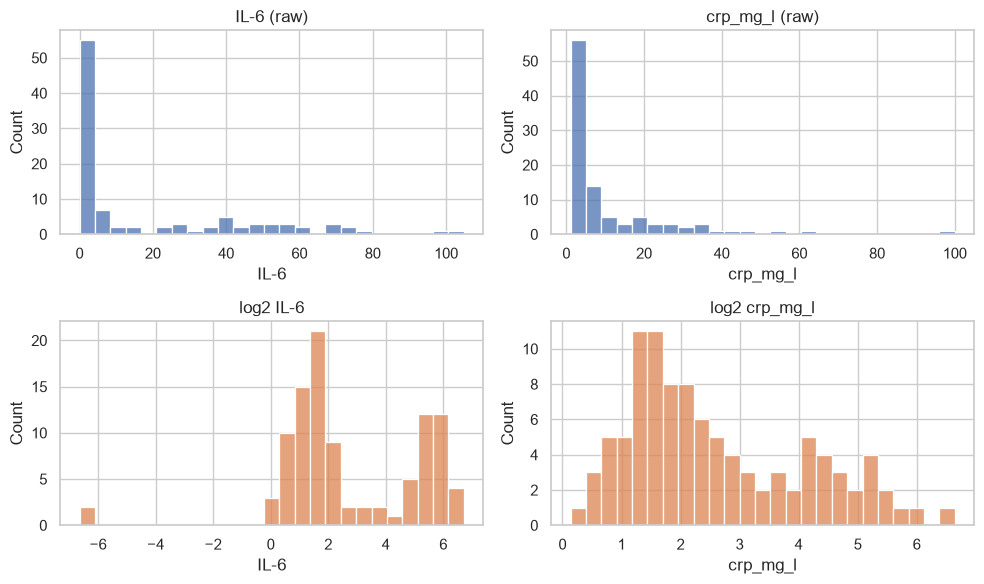

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for col, (ax_raw, ax_log) in zip(["IL-6", "crp_mg_l"], axes.T):
    sns.histplot(df[col], ax=ax_raw, bins=25)
    ax_raw.set_title(f"{col} (raw)")
    sns.histplot(np.log2(df[col]), ax=ax_log, bins=25, color="C1")
    ax_log.set_title(f"log2 {col}")
plt.tight_layout()

In [5]:
# Work on log2 scale from here on. Clean names make formulas easier.
d = pd.DataFrame({
    "log_crp": np.log2(df["crp_mg_l"]),
    "log_esr": np.log2(df["esr_mm_h"]),
    "ra": df["ra_status"],
    "age": df["age"],
    "bmi": df["bmi"],
    "female": (df["gender"] == "F").astype(int),
    "smoking": df["smoking"],
    "disease_duration": df["disease_duration"],
})
for c in CYTOKINES:
    d["log_" + c.replace("-", "_")] = np.log2(df[c])
LOG_CYT = [c for c in d.columns if c.startswith("log_") and c not in ("log_crp", "log_esr")]
d.head()

,log_crp,log_esr,ra,age,bmi,female,smoking,disease_duration,log_TNF_alpha,log_IL_1beta,log_IL_6,log_IL_8,log_IL_10,log_IL_17A,log_IL_18,log_IFN_gamma,log_MCP_1,log_VEGF
0,5.157852,5.321928,1,43,25.3,1,1,11.6,5.238787,2.500802,6.262095,4.817623,1.389567,4.135863,9.022118,3.893362,9.301153,9.699225
1,0.765535,3.169925,0,56,28.3,0,0,0.0,2.289834,-0.971431,0.722466,3.489286,2.277985,2.039138,6.904966,2.077243,8.010052,8.184131
2,3.017922,3.906891,0,60,34.3,0,0,0.0,1.944858,-0.971431,2.094236,2.961623,1.438293,2.400538,6.879583,3.111031,8.592382,6.541639
3,2.104337,3.700440,0,51,27.9,0,0,0.0,3.201634,1.070389,1.526069,1.580145,2.166715,0.111031,6.319762,3.843984,8.207893,6.231893
4,1.485427,3.000000,0,26,25.1,1,0,0.0,1.794936,1.361768,-0.168123,3.294253,1.207893,1.250962,6.437461,3.053111,9.135248,8.307565


## 3. Simple linear regression — by hand first

Question: **does IL-6 predict CRP?** Biologically plausible: IL-6 drives hepatic CRP production.

Model: $\hat{y} = \beta_0 + \beta_1 x$, with $x$ = log2 IL-6, $y$ = log2 CRP.

Least squares picks $\beta_0, \beta_1$ minimising $\text{SSR} = \sum_i (y_i - \hat{y}_i)^2$. For one feature there is a closed form:

$$\beta_1 = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2}, \qquad \beta_0 = \bar y - \beta_1 \bar x$$

In [6]:
x = d["log_IL_6"].to_numpy()
y = d["log_crp"].to_numpy()

b1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
b0 = y.mean() - b1 * x.mean()
y_hat = b0 + b1 * x

ssr = np.sum((y - y_hat) ** 2)          # what the model fails to explain
sst = np.sum((y - y.mean()) ** 2)       # total variation around the mean
r2 = 1 - ssr / sst
print(f"intercept = {b0:.3f}, slope = {b1:.3f}, R² = {r2:.3f}")
print(f"Interpretation: doubling IL-6 multiplies CRP by 2^{b1:.3f} = {2**b1:.2f}x")

intercept = 1.624, slope = 0.353, R² = 0.335
Interpretation: doubling IL-6 multiplies CRP by 2^0.353 = 1.28x


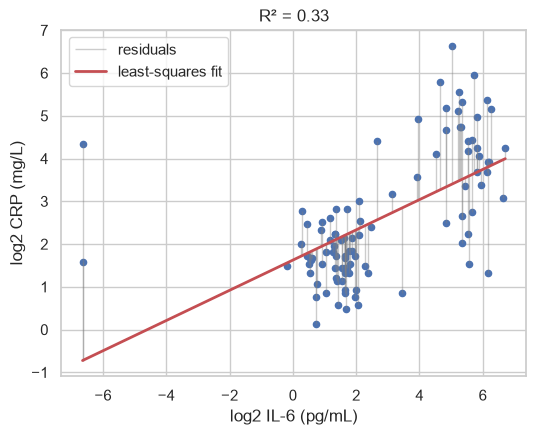

In [7]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.vlines(x, y, y_hat, color="grey", alpha=0.4, lw=1, label="residuals")
ax.scatter(x, y, s=20)
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, b0 + b1 * xs, color="C3", lw=2, label="least-squares fit")
ax.set(xlabel="log2 IL-6 (pg/mL)", ylabel="log2 CRP (mg/L)", title=f"R² = {r2:.2f}")
ax.legend();

### The loss landscape (a teaser for Day 2)

Least squares is "the slope at the bottom of the loss curve". Below we fix the intercept and plot SSR for many candidate slopes. On Day 2, **gradient descent** will walk down this curve step by step — essential when there's no closed form (logistic regression, neural nets).

In [8]:
slopes = np.linspace(b1 - 0.6, b1 + 0.6, 200)
losses = [np.sum((y - (y.mean() - s * x.mean() + s * x)) ** 2) for s in slopes]
plt.figure(figsize=(6, 3.5))
plt.plot(slopes, losses)
plt.axvline(b1, color="C3", ls="--", label=rf"optimum $eta_1$ = {b1:.2f}")
plt.xlabel(r"slope $eta_1$"); plt.ylabel("SSR"); plt.legend();

Error in callback <function _draw_all_if_interactive at 0x000001CC2EFB3BA0> (for post_execute), with arguments args (),kwargs {}:


ValueError: 
slope $eta_1$
      ^
ParseException: Expected end of text, found '$'  (at char 6), (line:1, col:7)

ValueError: 
slope $eta_1$
      ^
ParseException: Expected end of text, found '$'  (at char 6), (line:1, col:7)

<Figure size 600x350 with 1 Axes>

### Same thing with libraries

- **statsmodels** → statistics view: standard errors, p-values, CIs.
- **scikit-learn** → ML view: `fit` / `predict`, plugs into pipelines and cross-validation.

In [9]:
m1 = smf.ols("log_crp ~ log_IL_6", data=d).fit()
print(m1.summary().tables[1])

lr = LinearRegression().fit(d[["log_IL_6"]], d["log_crp"])
print(f"\nsklearn: intercept = {lr.intercept_:.3f}, slope = {lr.coef_[0]:.3f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.6243      0.185      8.777      0.000       1.257       1.992
log_IL_6       0.3535      0.050      7.020      0.000       0.254       0.453

sklearn: intercept = 1.624, slope = 0.353


## 4. 🚨 The confounding trap

R² ≈ 0.33 and p < 10⁻⁹. Paper-ready? Colour the points by disease status first.

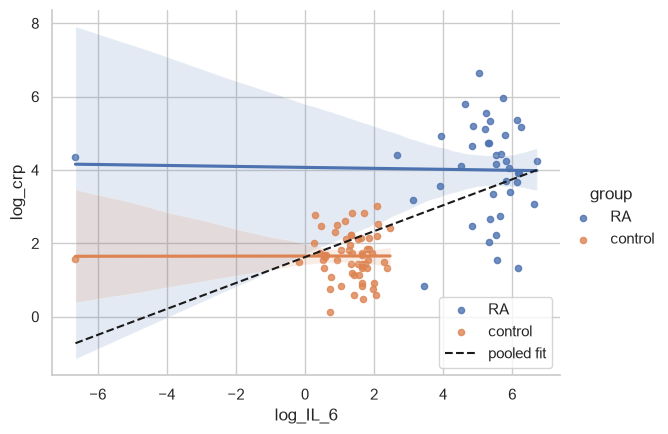

In [10]:
g = sns.lmplot(data=d.assign(group=d["ra"].map({0: "control", 1: "RA"})),
               x="log_IL_6", y="log_crp", hue="group", height=4.5, aspect=1.3,
               scatter_kws={"s": 20})
g.ax.plot(xs, b0 + b1 * xs, color="k", ls="--", lw=1.5, label="pooled fit")
g.ax.legend();

In [11]:
m2 = smf.ols("log_crp ~ log_IL_6 + ra", data=d).fit()
print(pd.DataFrame({
    "IL-6 slope": [m1.params["log_IL_6"], m2.params["log_IL_6"]],
    "p-value":    [m1.pvalues["log_IL_6"], m2.pvalues["log_IL_6"]],
    "R²":         [m1.rsquared, m2.rsquared],
}, index=["CRP ~ IL-6", "CRP ~ IL-6 + RA"]).round(4))

                 IL-6 slope  p-value      R²
CRP ~ IL-6           0.3535   0.0000  0.3346
CRP ~ IL-6 + RA     -0.0085   0.8889  0.5937


**Within each group, IL-6 carries no information about CRP.** The pooled correlation exists only because RA patients have higher values of *both*. Opening `data-generation.qmd` confirms it: CRP was simulated from disease status alone.

```
        RA status
        ↙      ↘
     IL-6       CRP      ← no arrow between them
```

Lessons that transfer directly to real cohorts:
- A good **predictor** is not necessarily a **mechanism**. For prediction, IL-6 *is* useful (it tracks disease). For biology, it's misleading.
- Always ask *what else differs between the samples* — disease status, batch, site, age, sex, sample processing date.
- In clinical omics, plot by group/batch **before** trusting any pooled correlation.

## 5. Train/test split — measuring generalisation

R² on the data used for fitting is **optimistic**: the model has seen those answers. To estimate performance on *new patients* we hide a test set and never touch it during fitting.

We **stratify** by RA status so both sets have the same case/control ratio (important with small, imbalanced cohorts).

In [12]:
train, test = train_test_split(d, test_size=0.3, random_state=SEED, stratify=d["ra"])
print(f"train: {len(train)} patients ({train['ra'].mean():.0%} RA) | "
      f"test: {len(test)} patients ({test['ra'].mean():.0%} RA)")

train: 70 patients (40% RA) | test: 30 patients (40% RA)


### Overfitting, visually

Let's fit increasingly flexible curves (polynomials of degree 1 … 12) of IL-6 → CRP. Flexibility always reduces training error — but at some point the model fits **noise**, and test error rises.

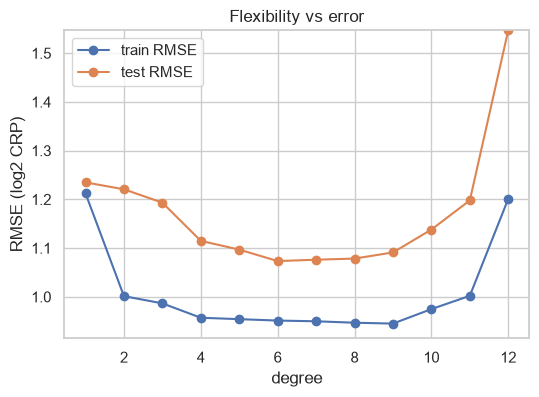

In [13]:
degrees = range(1, 13)
rows = []
for k in degrees:
    model = make_pipeline(StandardScaler(), PolynomialFeatures(k), LinearRegression())
    model.fit(train[["log_IL_6"]], train["log_crp"])
    rows.append({
        "degree": k,
        "train RMSE": mean_squared_error(train["log_crp"], model.predict(train[["log_IL_6"]])) ** 0.5,
        "test RMSE":  mean_squared_error(test["log_crp"],  model.predict(test[["log_IL_6"]])) ** 0.5,
    })
res = pd.DataFrame(rows).set_index("degree")
ax = res.plot(marker="o", figsize=(6, 4), ylabel="RMSE (log2 CRP)",
              title="Flexibility vs error")
ax.set_ylim(top=min(res.values.max(), 3 * res["test RMSE"].min()));

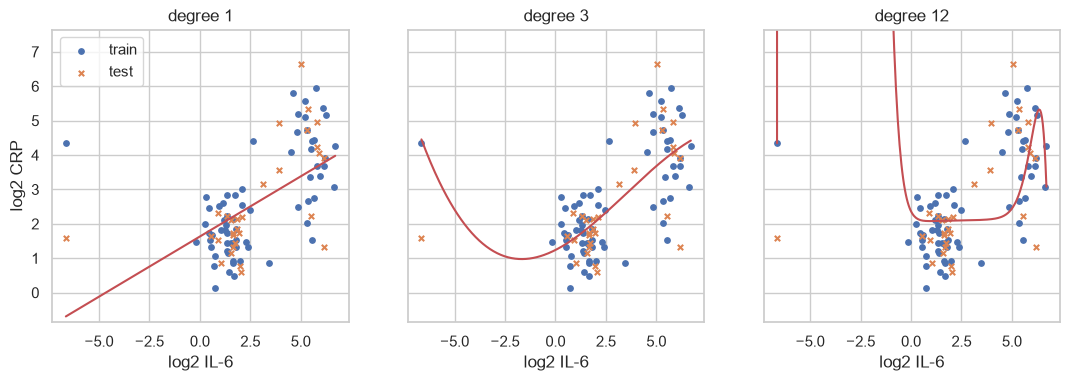

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
grid = pd.DataFrame({"log_IL_6": np.linspace(d["log_IL_6"].min(), d["log_IL_6"].max(), 300)})
for ax, k in zip(axes, [1, 3, 12]):
    model = make_pipeline(StandardScaler(), PolynomialFeatures(k), LinearRegression())
    model.fit(train[["log_IL_6"]], train["log_crp"])
    ax.scatter(train["log_IL_6"], train["log_crp"], s=15, label="train")
    ax.scatter(test["log_IL_6"], test["log_crp"], s=15, marker="x", label="test")
    ax.plot(grid["log_IL_6"], model.predict(grid), color="C3")
    ax.set(title=f"degree {k}", xlabel="log2 IL-6", ylim=(d["log_crp"].min() - 1, d["log_crp"].max() + 1))
axes[0].set_ylabel("log2 CRP"); axes[0].legend();

**Bias–variance trade-off in one sentence:** too simple → misses real structure (*bias*); too flexible → memorises the training patients' noise (*variance*). The sweet spot is found on data the model hasn't seen.

## 6. Multiple regression — and why omics breaks it

Now use **all** 10 cytokines plus age, BMI, sex and smoking as features (14 predictors, 70 training patients).

In [15]:
FEATURES = LOG_CYT + ["age", "bmi", "female", "smoking"]

def evaluate(features, train=train, test=test, target="log_crp"):
    model = make_pipeline(StandardScaler(), LinearRegression())
    model.fit(train[features], train[target])
    return (r2_score(train[target], model.predict(train[features])),
            r2_score(test[target],  model.predict(test[features])),
            model)

r2_tr, r2_te, mlr = evaluate(FEATURES)
print(f"{len(FEATURES)} features -> train R² = {r2_tr:.2f}, test R² = {r2_te:.2f}")

14 features -> train R² = 0.58, test R² = 0.40


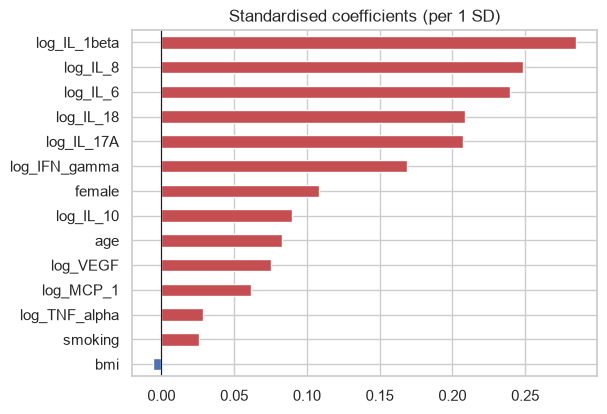

In [16]:
coefs = pd.Series(mlr[-1].coef_, index=FEATURES).sort_values()
coefs.plot.barh(figsize=(6, 4.5), title="Standardised coefficients (per 1 SD)",
                color=np.where(coefs > 0, "C3", "C0"))
plt.axvline(0, color="k", lw=0.8);

Standardising (`StandardScaler`) puts all coefficients on the same scale: *change in log2 CRP per 1 SD of the feature*. Note the scaler is inside the pipeline and is **fit on training data only** — scaling on the full dataset before splitting is a classic, subtle **data leakage**.

### The p ≫ n problem

Omics panels routinely have more features than patients (proteomics: thousands of proteins, 20–200 samples). Let's simulate that by adding pure-noise "proteins" — features with **zero** true relationship to CRP.

In [17]:
rng = np.random.default_rng(SEED)
results = []
for n_noise in [0, 10, 25, 40, 55, 65, 100, 300]:
    noise = pd.DataFrame(rng.normal(size=(len(d), n_noise)), index=d.index,
                         columns=[f"noise_{i}" for i in range(n_noise)])
    dn = pd.concat([d, noise], axis=1)
    tr, te = dn.loc[train.index], dn.loc[test.index]
    r2_tr, r2_te, _ = evaluate(FEATURES + list(noise.columns), tr, te)
    results.append({"n features": len(FEATURES) + n_noise, "train R²": r2_tr, "test R²": r2_te})
res_p = pd.DataFrame(results).set_index("n features")
res_p.round(2)

,train R²,test R²
n features,,
14,0.58,0.40
24,0.64,0.14
39,0.75,0.25
54,0.91,-1.73
69,1.00,-12.71
79,1.00,-5.35
114,1.00,-0.06
314,1.00,0.18


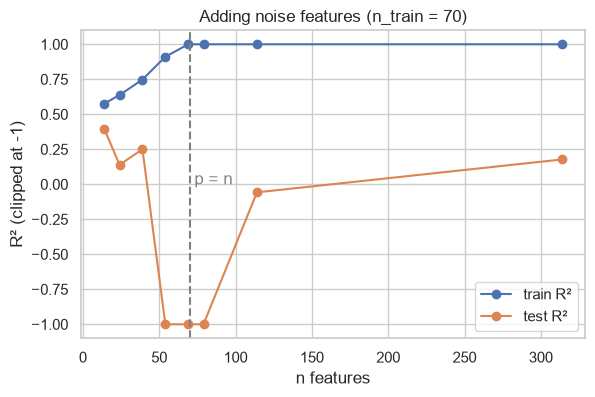

In [18]:
ax = res_p.clip(lower=-1).plot(marker="o", figsize=(6.5, 4), title="Adding noise features (n_train = 70)")
ax.axvline(len(train), color="grey", ls="--"); ax.text(len(train) + 3, 0.0, "p = n", color="grey")
ax.set_ylabel("R² (clipped at -1)");

Once *p* approaches *n*, ordinary least squares can fit the training data **perfectly** (train R² → 1) using noise alone, while test performance collapses. With p > n there are infinitely many perfect solutions — the model is underdetermined.

*Side note:* far beyond p = n, test R² creeps back up. With p > n, scikit-learn returns the *minimum-norm* solution, which acts as implicit regularisation (the "double descent" phenomenon also seen in neural nets). It's still worse than the honest 14-feature model and highly unstable. Don't rely on it.

This is exactly why omics biomarker discovery needs **regularisation** (LASSO / ridge / elastic net — Day 3) and honest **cross-validation**. Your PLS-DA + LASSO workflows from the aging proteomics data (2,500 proteins, 23 samples) live squarely in this regime.

## 7. Pitfalls checklist for clinical / omics regression

- [ ] Plot distributions; log-transform concentrations; note LOD-floored values.
- [ ] Colour by group, batch, site **before** trusting correlations (confounding).
- [ ] Split **by patient** — repeated measures/technical replicates of one patient must stay on the same side.
- [ ] Fit every preprocessing step (scaling, imputation, feature selection!) on **train only**.
- [ ] Report test-set (or cross-validated) performance, not training R².
- [ ] With small *n*, a single split is noisy → cross-validation (Day 3).
- [ ] p ≫ n → regularise.

## 8. Exercises

Try them first; solutions follow each one.

**Exercise 1.** ESR is another inflammation marker. Fit `log_esr ~ log_IL_6`, then `log_esr ~ log_IL_6 + ra`. Is the IL-6 story the same as for CRP?

In [19]:
# your code here

In [20]:
# Solution 1
for f in ["log_esr ~ log_IL_6", "log_esr ~ log_IL_6 + ra"]:
    m = smf.ols(f, data=d).fit()
    print(f"{f:28s} IL-6 slope = {m.params['log_IL_6']:.3f}  p = {m.pvalues['log_IL_6']:.3g}  R² = {m.rsquared:.2f}")
# Same story: adjusting for RA status removes the IL-6 association.

log_esr ~ log_IL_6           IL-6 slope = 0.326  p = 5.1e-10  R² = 0.33
log_esr ~ log_IL_6 + ra      IL-6 slope = -0.022  p = 0.688  R² = 0.60


**Exercise 2.** How noisy is a single train/test split with n = 100? Repeat the 14-feature regression on 200 different random splits (`random_state=i`) and plot the distribution of test R².

In [21]:
# your code here

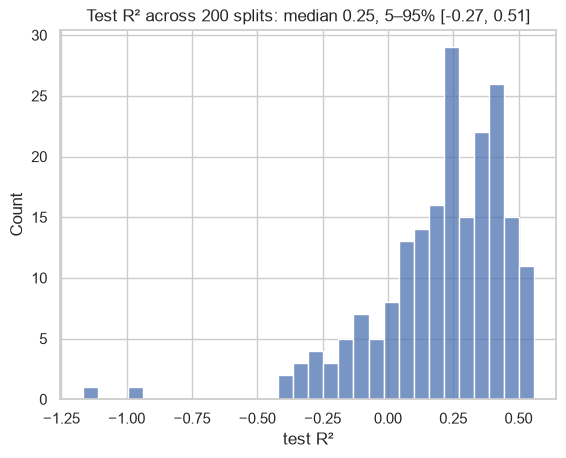

In [22]:
# Solution 2
scores = []
for i in range(200):
    tr, te = train_test_split(d, test_size=0.3, random_state=i, stratify=d["ra"])
    scores.append(evaluate(FEATURES, tr, te)[1])
scores = np.array(scores)
sns.histplot(scores, bins=30)
plt.title(f"Test R² across 200 splits: median {np.median(scores):.2f}, "
          f"5–95% [{np.percentile(scores, 5):.2f}, {np.percentile(scores, 95):.2f}]")
plt.xlabel("test R²");
# One split can make the same model look good or bad -> motivation for cross-validation.

**Exercise 3.** Within RA patients only, does `disease_duration` predict any cytokine? Loop over the 10 log-cytokines, fit `cytokine ~ disease_duration`, and collect the p-values. How many would you call "significant" at 0.05 — and what should you do about testing 10 hypotheses?

In [23]:
# your code here

In [24]:
# Solution 3
from statsmodels.stats.multitest import multipletests

ra_only = d[d["ra"] == 1]
pvals = pd.Series({c: smf.ols(f"{c} ~ disease_duration", data=ra_only).fit().pvalues["disease_duration"]
                   for c in LOG_CYT})
out = pd.DataFrame({"p": pvals, "p_BH": multipletests(pvals, method="fdr_bh")[1]}).sort_values("p")
print(out.round(3))
# With 10 tests, ~0.5 false positives are expected at alpha = 0.05 even with no true effect.
# Control the FDR (Benjamini–Hochberg) — standard practice for omics panels.

                   p   p_BH
log_MCP_1      0.118  0.729
log_IL_6       0.146  0.729
log_TNF_alpha  0.328  0.989
log_IL_18      0.518  0.989
log_IL_17A     0.698  0.989
log_VEGF       0.706  0.989
log_IFN_gamma  0.788  0.989
log_IL_8       0.825  0.989
log_IL_10      0.890  0.989
log_IL_1beta   0.989  0.989


## Summary

| Concept | Takeaway |
|---|---|
| Linear regression | Least squares minimises squared residuals; slopes on log2 scale = fold-change per doubling |
| R² | Fraction of variance explained — **on training data it's optimistic** |
| Confounding | Strong pooled association can vanish within groups; always stratify/adjust |
| Train/test | The test set estimates performance on new patients |
| Overfitting | More flexibility ↓ train error, eventually ↑ test error |
| p ≫ n | OLS fits noise perfectly → need regularisation + CV |

**Next — Day 2: Logistic Regression + Gradient Descent.** We switch target to `ra_status`: classify RA vs control from the cytokine panel, learn gradient descent from scratch, and evaluate with ROC/AUC, sensitivity/specificity and calibration — the metrics clinicians actually ask for.